# Gene loadings: Interpretability

In [1]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import seaborn as sns
from scipy.sparse import csr_array, csr_matrix, issparse
import interscale

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects" 
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'
DATA = "legnini23"

HPC cluster


In [3]:
import yaml
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]
#CELL_TYPE_COLORS = config["palettes"][DATA]

slides = config["slide_examples"]["legnini23"]

<mark>TODO: Change data path</mark>

In [4]:
LRZ_LEGNINI23 = f'{BASE_DIR_PROJECT}/data/{DATA}_pp.h5ad'  

## Load data

In [5]:
adata = sc.read_h5ad(LRZ_LEGNINI23)
adata

AnnData object with n_obs × n_vars = 43762 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone', 'cell_type', 'sliding_window_low', 'sliding_window_high_SHH_near_medium', 'sliding_window_high_near_medium_far'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

In [6]:
print('Zero count cells: ', (adata.X.sum(1) ==0).sum())

Zero count cells:  648


## Load trained models

In [7]:
import sys

project_root = Path(BASE_DIR_REPO)  # InterScale_reproducibility, for `from src.wandb import ...`
sys.path.insert(0, str(project_root))

# The interscale package is a SIBLING of InterScale_reproducibility, not a subdirectory of it, so
# `Path(BASE_DIR_REPO) / "interscale"` points at nothing here. It only resolved in
# 3_sliding_window_ablation.ipynb, where BASE_DIR_REPO is the A3_InterScale root.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "legnini23"

# ---------------------------------------------------------------------------------------------
# WHICH MASKING ARM TO LOAD.  Flip this and re-run from here; nothing below is arm-specific.
#
#   "cell"  whole cells are blanked and all G genes of them are scored  (mask_strategy "node")
#   "gene"  individual (cell, gene) entries are blanked and only those are scored
#
# The two sweeps below are matched: same five seeds, same 300 epochs, same architecture, and both
# trained with MASK_VALUE = -1. They differ only in masking granularity and its rate, so a
# difference in how stable the gene loadings are across seeds is attributable to that.
#
# The rate is not the same number in the two arms because it is not the same quantity: 0.30 of
# the CELLS vs 0.25 of every cell's GENES. 0.25 is where gene masking measurably wins
# (val_concordance_corr 0.1947 +/- 0.0041 against cell 0.30's 0.1634 +/- 0.0084, 3 seeds).
#
# NOTE these are NOT the published seed_stability/ models. Those were trained at the old 100-epoch
# default with MASK_VALUE = 0 and are left untouched in `.../legnini23_revision/seed_stability/`.
# 300 epochs because at 100 no trial on this dataset ever early-stops (optim.min_delta is 0.0, so
# only the n_epochs cap stops a run) and 100 -> 300 moves val_concordance_corr by +200% to +286%;
# seed spread is 2-18% at 100 and 1-4% at 300, so a stability analysis at 100 would largely be
# measuring undertraining.
# ---------------------------------------------------------------------------------------------
MASKING = "cell"  # "cell" | "gene"

ARMS = {
    "cell": {
        "task": "node_reg",
        "sweep_id": "ze40fzaz",  # config_files/sweeps/seed_cell_masking.yaml
        "models_subdir": "seed_stability_cell",
        # Nothing to override: node_reg's registry defaults are what the sweep trained with.
        "overrides": {},
    },
    "gene": {
        "task": "node_reg_genemask",
        "sweep_id": "dty3dlk3",  # config_files/sweeps/seed_gene_masking.yaml
        "models_subdir": "seed_stability_gene",
        # The sweep pinned the rate below the task file's 0.5; build_cfg has to reapply it or the
        # config recorded here is not the one that trained. (It changes no tensor shape, so
        # loading would succeed either way -- which is exactly why it would go unnoticed.)
        "overrides": {"dataset.mask_percentage": 0.25},
    },
}
assert MASKING in ARMS, f"MASKING must be one of {sorted(ARMS)}"
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]

MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "legnini23_revision" / ARM["models_subdir"]
# Per-arm, so the two arms' per-gene CSVs can sit side by side instead of overwriting each other.
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"rec_seed_stablity_{MASKING}"

assert REGISTRY.exists(), f"registry not found: {REGISTRY}"
assert MODELS_DIR.exists(), (
    f"checkpoint dir not found: {MODELS_DIR}\n"
    f"Train it with:  SWEEP_ID={SWEEP_ID} sbatch scripts/run.sh {DATASET} {TASK} "
    f"--sweep_cfg config_files/sweeps/seed_{MASKING}_masking.yaml --sweep_goal robustness --count 5"
)
print(f"masking     {MASKING} (task {TASK}, sweep {SWEEP_ID})")
print(f"registry    {REGISTRY}\ncheckpoints {MODELS_DIR}\nresults     {RESULTS_DIR}")


masking     cell (task node_reg, sweep ze40fzaz)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_cell
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23/rec_seed_stablity_cell


In [8]:
import os
from pathlib import Path

import wandb

from interscale.evaluation import plot_global_directionality
from interscale.evaluation.net_streams import compute_hierarchical_net_flow
from interscale.tl.utils import set_full_reproducibility
from src.wandb import Wandb_evaluation, plot_f1_across_seeds

# Everything that used to be defined inline in this notebook now lives in
# src/decoder_stability.py, so that notebooks/Cosmx/4_decoder_stability_cosmx.ipynb runs the
# SAME selection code rather than a copy of it. The two notebooks are meant to be a
# like-for-like comparison of loading stability across two datasets, and that only holds if
# the gene-selection code is literally shared.
#
# `expected_intersection` used to be imported from interscale.tl.utils, where it does not
# exist -- it lives in src/utils.py, now next to `intersection_tail_probability`, which
# `tail_prob_by_k` needs and which this notebook previously relied on being left in the
# kernel by a cell that has since been deleted. Both are re-exported here.
from src.decoder_stability import (
    GROUP_COLORS,
    build_cfg as _build_cfg,
    collect_gene_sets,
    expected_intersection,
    intersection_by_k,
    intersection_tail_probability,
    local_global_split,
    overlap_matrix,
    per_gene_metrics,
    plot_intersection_by_k,
    plot_membership,
    plot_tail_prob_by_k,
    run_seed_inference,
    tail_prob_by_k,
)

wandb.login()

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.
wandb: Currently logged in as: francesca-drummer to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Load WandB sweep

Load sweep from WandB (5 seeds, all the same model parameters)

In [9]:
# NOT `wandb = ...`: that name is the wandb module, imported two cells up, and rebinding it is
# what made `wandb.Api(timeout=60)` raise AttributeError further down.
#
# SWEEP_ID comes from the MASKING switch above. The first argument is only a label --
# Wandb_evaluation hardcodes entity/project to francesca-drummer/InterScale_hyperparameter_sweep.
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)


In [10]:
sweep_df = sweep_eval.get_dataframe()
sweep_df.head()

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,t3cxaxb3,dual_legnini23_regr_node_40_GCN_self-attn-tran...,40,finished,0.3,node,0.3,None,None,153,51168,-1.386118,0.312122
1,phmtuc86,dual_legnini23_regr_node_41_GCN_self-attn-tran...,41,finished,0.3,node,0.3,None,None,252,51168,-0.682518,0.326741
2,9p9ixuw9,dual_legnini23_regr_node_42_GCN_self-attn-tran...,42,finished,0.3,node,0.3,None,None,238,51168,-0.278964,0.335235
3,lshqnbqa,dual_legnini23_regr_node_43_GCN_self-attn-tran...,43,finished,0.3,node,0.3,None,None,256,51168,-0.259736,0.345807
4,rjo32qaa,dual_legnini23_regr_node_44_GCN_self-attn-tran...,44,finished,0.3,node,0.3,None,None,233,51168,-0.294231,0.350113


## Model inference

Load each of the five seed models, run inference, and keep

- `local_emb[seed]` / `global_emb[seed]` &mdash; the two embeddings, `(n_cells, n_embed)`
- `models[seed]` &mdash; the loaded `CombinedModel`, for the gene-loading section below
- `performance[seed]` &mdash; per-gene reconstruction scores, also written to
  `results/legnini23/rec_seed_stablity/model_{seed}_performance.csv`

The models are loaded from disk rather than from wandb artifacts: the sweep pinned `model.save`,
so all five checkpoints already sit in `legnini23_revision/seed_stability/`.

**The seed cannot be read off `run.config['optim']['seed']`.** `main_sweep.py` calls
`wandb.init(config=cfg)` *before* `apply_sweep_config`, so the nested config wandb stored is the
base config &mdash; seed 44 for all five runs, which is also why every run is named `..._44_...`.
Only the flattened `run.config['optim.seed']` (what `sweep_df["seed"]` reads) carries the trial's
actual value, and it is what `build_cfg` applies below.

In [11]:
from functools import partial

# `config_files/sweeps/seed_{cell,gene}_masking.yaml` declare optim.seed over [40..44], a fixed
# optim.n_epochs and model.save, and -- for the gene arm only -- a fixed
# dataset.mask_percentage. Reapplying those on top of the resolved (DATASET, TASK) pair
# reproduces the config each trial trained with; everything else (radius 200, n_embed 16,
# dual_decoder) comes from the registry, unchanged.
#
# optim.seed is not cosmetic: get_model_filename_prefix puts it in the checkpoint name, which
# is what makes the five models separable when load() picks the file. The same prefix also
# carries dataset.name, which the registry sets to legnini23_genemask for the gene arm -- so
# the two arms' checkpoints are distinguishable even before the directory split.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=MODELS_DIR,
    overrides={"optim.n_epochs": 300, **ARM["overrides"]},
)

# per_gene_metrics is imported from src.decoder_stability; run_seed_inference calls it.

In [12]:
from interscale.tl import remove_zero_expression_cells

# Training ran on the zero-expression-filtered adata (43762 -> 43114 cells here). Inference has to
# filter identically, or the per-sample graphs handed to the model are not the graphs it was
# trained on.
#
# remove_zero_expression_cells reads adata.X, and a cell further down repoints adata.X at
# log1p_norm -- where no cell sums to zero, so re-running this cell after that one would silently
# keep all 43762. layers['raw'] is the same matrix X holds on load (identical nnz, identical 648
# zero rows), so restoring it first makes this cell order-independent.
adata.X = adata.layers["raw"]
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)

cfg0 = build_cfg(SEEDS[0])
window_key = cfg0.dataset.sample_key[0]
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

# Below max_seq_len, tl/padding.py random-subsamples each graph every call instead of erroring,
# so the predictions would come from a graph the model never saw.
sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} graph is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")

# Ground truth is the layer the decoders were trained to reconstruct, NOT .X -- this h5ad keeps
# counts in X (max ~120) against log1p-scale predictions (max ~4.8).
_y_true = adata.layers[cfg0.dataset.layer_key]
y_true = np.asarray(_y_true.todense() if issparse(_y_true) else _y_true, dtype=np.float64)

DECODERS = {"local": "_y_pred_local", "global": "_y_pred_global"}
# 'all' first so the csv leads with the number over every cell; the three real splits follow so
# the test rows stay comparable to the sweep's `test_r2` / `test_pearson_corr` columns.
SPLITS = ["all", "train", "val", "test"]

Nr. of zero expression cells: 648
seeds: [40, 41, 42, 43, 44]
17 graphs over 'sample', largest 4299 cells (max_seq_len 4318)


In [13]:
# Writes obsm[f"{seed}_local_emb"] / obsm[f"{seed}_global_emb"] and
# layers[f"{seed}_y_pred_local"] / layers[f"{seed}_y_pred_global"] into adata, plus one
# per-gene csv per seed under RESULTS_DIR. The seed prefix is what lets the gene-loading
# section below revisit any seed, not only the last one inferred.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    MODELS_DIR,
    RESULTS_DIR,
    y_true=y_true,
    # 40 for every model, which is what this notebook has always done. Nothing stochastic
    # happens between the load and the forward pass, so it does not change the predictions --
    # but it is stated here rather than inherited from whatever was last in scope.
    repro_seed=40,
)

Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_cell/dual_legnini23_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.        

## Gene loadings

In [14]:
from interscale.evaluation import (
    gene_loadings,
    calculate_gene_ranks,
    latent_rank_report,
    get_genes_dim,
    calculate_dim_importance,
)

In [15]:
adata

AnnData object with n_obs × n_vars = 43114 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone', 'cell_type', 'sliding_window_low', 'sliding_window_high_SHH_near_medium', 'sliding_window_high_near_medium_far', '_scvi_sample_key_0', '_scvi_split_key', '40_cls_horizontal', '40_cls_vertical', '41_cls_horizontal', '41_cls_vertical', '42_cls_horizontal', '42_cls_vertical', '43_cls_horizontal', '43_cls_vertical', '44_cls_horizontal', '44_cls_vertical'
    var: 'gene_ids', 'feature_types'
    uns: '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'spatial', '40_local_emb', '40_global_emb', '40_attn_matrix', '41_local_emb', '41_global_emb', '41_attn_matrix', '42_local_emb', '42_global_emb', '42_attn_matrix', '43_local_emb', '43_global_emb', '43_attn_matrix', '44_local_emb', '44_global_emb', '44_attn_matrix'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X), '40_y_pred_local', '40_y_pred_global', '41_y_pred_local', '41_y_p

In [16]:
print(SEEDS, models)

[40, 41, 42, 43, 44] {40: <interscale.model.combined_model.CombinedModel object at 0x7fb51c0ab8f0>, 41: <interscale.model.combined_model.CombinedModel object at 0x7fb66cbeb5c0>, 42: <interscale.model.combined_model.CombinedModel object at 0x7fb515543fe0>, 43: <interscale.model.combined_model.CombinedModel object at 0x7fb514c29220>, 44: <interscale.model.combined_model.CombinedModel object at 0x7fb516f3fe90>}


In [98]:
SEED = SEEDS[0]


60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[9, 13, 7]

60% cumulative variance reached with 5 dimensions:
Embedding dimensions (sorted by importance):
[13, 12, 7, 11, 9]


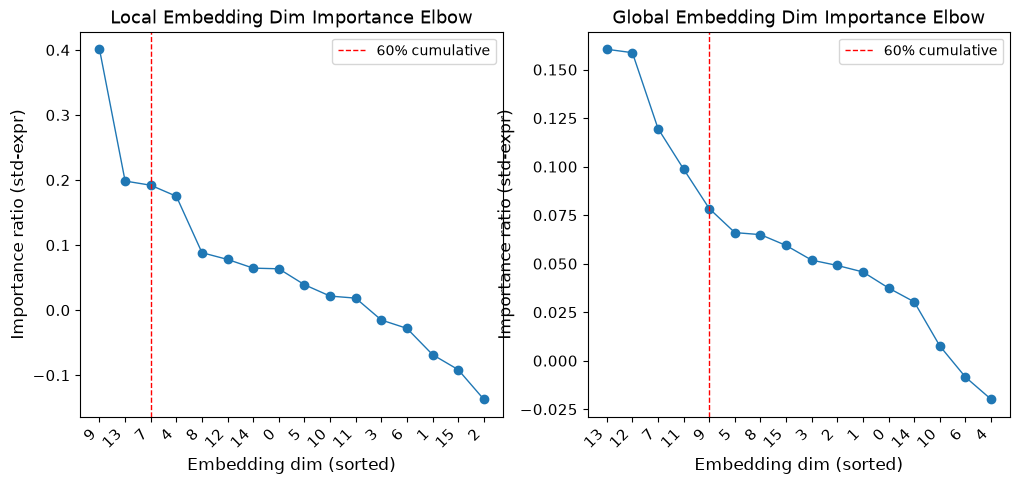

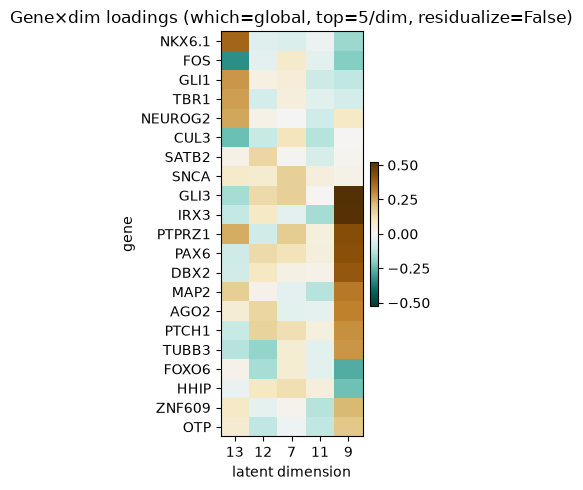

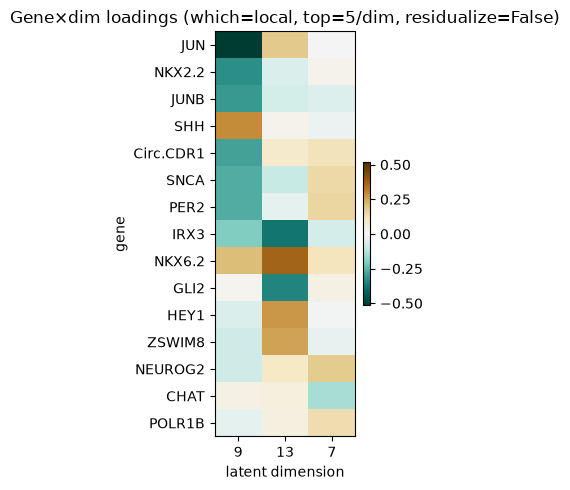

In [99]:
set_full_reproducibility(40)
gene_loadings(
    adata,
    models[SEED],
    local_latent_key=f"{SEED}_global_emb",
    global_latent_key=f"{SEED}_global_emb",
    local_varm_key=f"{SEED}_local_std_gene_loadings",
    global_varm_key=f"{SEED}_global_std_gene_loadings",
    layer_key="log1p_norm",
)

result_local = calculate_dim_importance(
    adata,
    which = "local", 
    prefix = SEED,
    mode="full",
    use_ratio=True,
    cumulative_cutoff=0.6,
    spacing=2,
)
result_global = calculate_dim_importance(
    adata,
    which = "global",
    prefix = SEED,
    mode="full",
    use_ratio=True,
    cumulative_cutoff=0.6,
    spacing=2,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
interscale.pl.dim_importance_elbow(result_local, title="Local Embedding Dim Importance Elbow", ax=axes[0])
interscale.pl.dim_importance_elbow(result_global, title="Global Embedding Dim Importance Elbow", ax=axes[1])

df_global, ax = get_genes_dim(
    adata,
    which="global",
    prefix = SEED,
    n_top=5,
    X_layer="log1p_norm",
    min_frac=0.0,
    rank_by="loading_x_sd",
    enforce_specificity=True,
    specificity_min=1.5,
    # residualize=True,
    plot=True,
    figsize=(3.3, 5),
)

df_local, ax = get_genes_dim(
    adata,
    which="local",
    prefix = SEED,
    n_top=5,
    X_layer="log1p_norm",
    min_frac=0.0,
    rank_by="loading_x_sd",
    enforce_specificity=True,
    specificity_min=1.5,
    # residualize=True,
    plot=True,
    figsize=(3.3, 5),
)

In [31]:
colors = []
for dim in adata.uns[f'{SEED}_local_dim_importance']['dims_left']:
    adata.obs[f'{SEED}_local_dim_{dim}'] = adata.obsm[f'{SEED}_local_emb'][:, dim]
    colors.append(f'{SEED}_local_dim_{dim}')

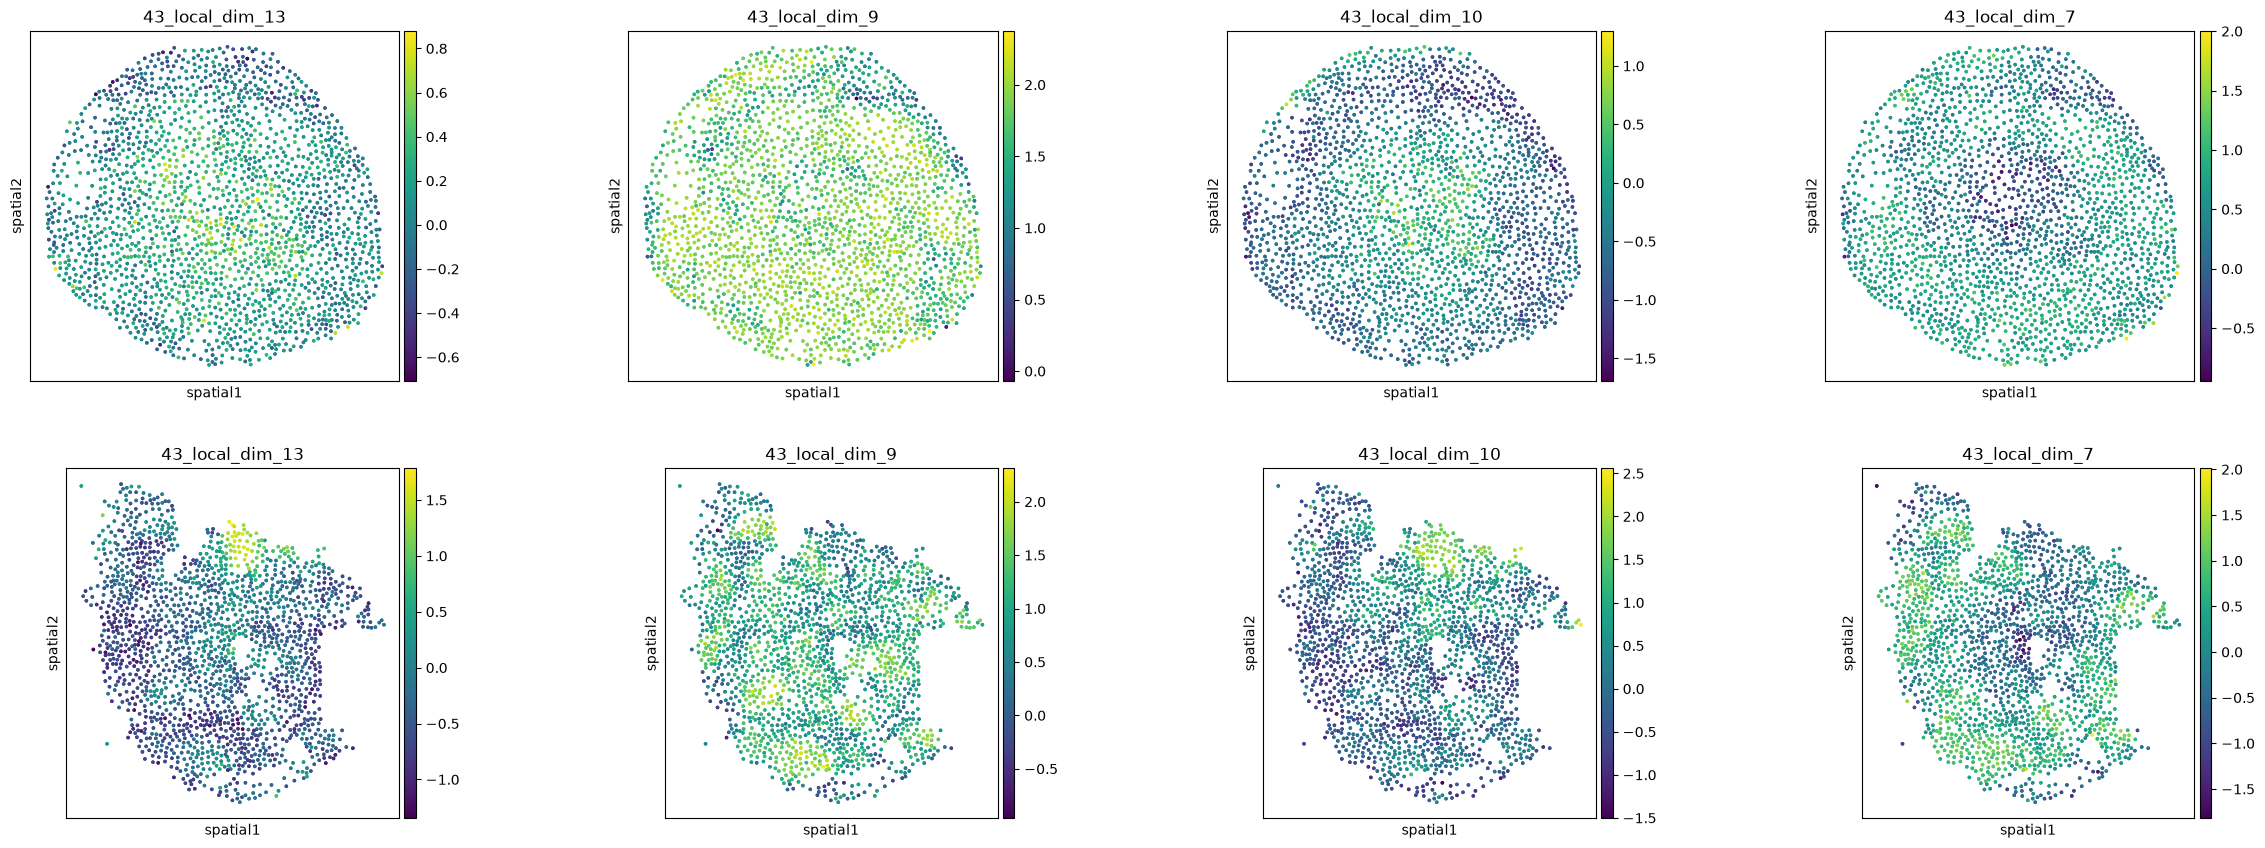

In [20]:
sq.pl.spatial_scatter(
    adata[adata.obs['sample'].isin([slides["Ctrl"], slides["SSH"]])],
    spatial_key = 'spatial',
    library_key='sample', 
    #library_id = [839, 6],
    color= colors,
    shape= None,
    size = 10,
)

## Concrete long-range interactions: anchor points and distance zones

> *"Concrete examples of long-range interactions captured by InterScale should be visualized
> and explained."*

The gene loadings above say *which* genes a global dimension drives. They do not say that the
dimension is long-range: a dimension whose genes all vary inside one cell's neighbourhood
would produce the same table. What follows localises the tissue a dimension is reading, and
then plots its genes against distance from that tissue.

Four steps, per global dimension (`interscale.tl.anchors`):

1. **Anchor points** &mdash; `find_anchor_cells` takes the tail of the dimension *within each
   slide* (a quantile, swept below) and keeps only tail cells that form a spatial focus:
   single-linkage at `link_radius`, discarding components under `min_cluster_size`. That
   second filter is what turns "the top 5% of cells" into a handful of anchor points;
   scattered high-score cells carry no location to measure a distance from.
2. **Signed distance** &mdash; `anchor_signed_distance` gives every cell its distance to the
   anchor *border*: negative inside a focus (how deep), positive outside. Zero is the border
   in both directions, so a profile is continuous across it. Distances are never measured
   across slides.
3. **Zones** &mdash; `anchor_zones` cuts that into `anchor core` / `near` / `far` at
   `near_max = local_reach_um(cfg)`, the furthest a cell's own representation can travel
   through the local component (`num_layers` hops of a radius-`radius` graph &mdash; 2 &times;
   200 um for this dataset). `near` is the band a purely local model could have explained;
   `far` is the band only the global component reaches.
4. **Gene behaviour across the zones** &mdash; the dimension's own top genes, mapped on the two
   example slides and profiled against the signed distance.

**The argument is the local-reach line.** A gene of a global dimension that is still changing
to the right of it is changing at a distance no cell's neighbourhood covers, which is what
makes it a long-range interaction rather than a neighbourhood effect. Every distance plot
marks the line.

The construction deliberately mirrors the fibrosis-core panels of a multi-organ supplement
(threshold a score into cores &rarr; signed distance to the core border &rarr; covariates
against that distance). The difference is that the core here is not an annotation: it is read
off the model.

In [21]:
from interscale.pl import (
    anchor_map,
    distance_profile,
    gene_maps,
    signed_distance_map,
    zone_map,
)
from interscale.tl import (
    anchor_enrichment,
    anchor_signed_distance,
    anchor_zones,
    find_anchor_cells,
    local_reach_um,
    profile_by_distance,
)

# Both publication slides, not just the SHH one. A dimension that anchored on the SHH graft
# has to come back with nothing on the control organoid, and that is only checkable side by
# side -- an anchor found on a Ctrl slide would say the threshold, not the biology, produced it.
EXAMPLE_SLIDES = [slides["Ctrl"], slides["SSH"]]
CONDITION = {s: adata.obs.loc[adata.obs["sample"] == s, "condition"].iloc[0] for s in EXAMPLE_SLIDES}
PANEL_TITLES = [f"{s}\n{CONDITION[s]}" for s in EXAMPLE_SLIDES]

# num_layers message-passing hops over a radius-`radius` graph: a hard bound on how far a
# cell's own expression can travel through the local component. 2 x 200 um here. Every
# distance below is read against this number.
REACH = local_reach_um(cfg0)

# Importance-ordered, from calculate_dim_importance above.
GLOBAL_DIMS = [int(d) for d in adata.uns[f"{SEED}_global_dim_importance"]["dims_left"]]
LOCAL_DIMS = [int(d) for d in adata.uns[f"{SEED}_local_dim_importance"]["dims_left"]]

FIG_DIR = Path(BASE_DIR_REPO) / "figures" / DATA / f"anchor_regions_{MASKING}"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """png for the notebook, pdf for the supplement."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")


print(f"seed {SEED}, masking {MASKING}")
print(f"local reach {REACH:g} um (radius {cfg0.dataset.spatial_neigbors_kwargs.radius} x "
      f"{cfg0.model.local_component.parameters.num_layers} hops)")
print(f"global dims kept: {GLOBAL_DIMS}")
print(f"figures -> {FIG_DIR}")

seed 43, masking cell
local reach 400 um (radius 200 x 2 hops)
global dims kept: [9, 13, 10, 1, 5, 6]
figures -> /home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/figures/legnini23/anchor_regions_cell


### Choosing the threshold

The quantile is the only real knob: *"few anchor points"* is a statement about how far into the
tail we go, and the model does not hand it over. So it is swept rather than asserted. The two
things to read off the table are `n_foci` (few, per the ask) and the per-slide anchor counts
(the Ctrl column should stay at or near zero for a dimension that is about the SHH graft).

`min_cluster_size` is 15 rather than the function's default 8: these slides hold ~1800-2000
cells, so a 0.95 tail is ~90-100 cells, and 15 is the size below which a "focus" is a few cells
that happen to sit together. `link_radius` is `REACH`, i.e. cells close enough that the local
component could have linked them already count as one focus.

In [33]:
MIN_CLUSTER_SIZE = 15
QUANTILES = (0.90, 0.95, 0.98, 0.99)
which = 'local'
if which == 'local': 
    DIMS = LOCAL_DIMS # GLOBAL_DIMS or LOCAL_DIMS
    df = df_local
elif which == 'global': 
    DIMS = GLOBAL_DIMS # GLOBAL_DIMS or LOCAL_DIMS
    df = df_global

rows = []
for dim in DIMS:
    for q in QUANTILES:
        a, f = find_anchor_cells(
            adata,
            f"{SEED}_global_emb",
            dim,
            quantile=q,
            link_radius=REACH,
            min_cluster_size=MIN_CLUSTER_SIZE,
            # Thresholds are per slide anyway; restricting keeps the sweep to the two slides
            # the figure shows instead of scoring all 17.
            samples=EXAMPLE_SLIDES,
        )
        rows.append(
            {
                "dim": dim,
                "quantile": q,
                "n_anchor": int(a.sum()),
                "n_foci": len(set(f[f >= 0])),
                **{s: int(a[(adata.obs["sample"] == s).to_numpy()].sum()) for s in EXAMPLE_SLIDES},
            }
        )

scan = pd.DataFrame(rows)
scan

,dim,quantile,n_anchor,n_foci,slide4_A2-3,slide4_B2-2
0,13,0.90,250,8,169,81
1,13,0.95,16,1,16,0
2,13,0.98,0,0,0,0
3,13,0.99,0,0,0,0
4,9,0.90,336,6,169,167
5,9,0.95,155,4,80,75
6,9,0.98,31,1,31,0
7,9,0.99,16,1,16,0
8,10,0.90,275,8,150,125
9,10,0.95,49,2,49,0


In [83]:
# Read off `scan`: the most important dimension (GLOBAL_DIMS is importance-ordered) that
# resolves into a handful of foci on the SHH slide, at the tightest threshold that still leaves
# any. Set DIM / QUANTILE by hand to look at a different dimension -- nothing below depends on
# how they were picked.
hits = scan[(scan[slides["SSH"]] > 0) & scan["n_foci"].between(1, 5)].copy()
assert not hits.empty, (
    "No global dimension resolved into 1-5 foci on the SHH slide. Widen QUANTILES or lower "
    "MIN_CLUSTER_SIZE -- but note that a dimension with no spatial focus is a result: it is a "
    "dimension that is not organised around a location, and it has no distance axis to plot."
)
hits["importance_rank"] = hits["dim"].map({d: i for i, d in enumerate(DIMS)})
hits = hits.sort_values(["importance_rank", "quantile"], ascending=[True, False])
DIM = int(hits.iloc[0]["dim"])
QUANTILE = float(hits.iloc[2]["quantile"])
print(f"dim {DIM} at quantile {QUANTILE}")
hits.head()

dim 9 at quantile 0.9


,dim,quantile,n_anchor,n_foci,slide4_A2-3,slide4_B2-2,importance_rank
5,9,0.95,155,4,80,75,1
13,7,0.95,88,2,71,17,3
12,7,0.90,258,5,149,109,3


In [91]:
DIM = 5
KEY = f"{SEED}_anchor_dim{DIM}"


anchor, focus = find_anchor_cells(
    adata,
    f"{SEED}_global_emb",
    DIM,
    quantile=QUANTILE,
    link_radius=REACH,
    min_cluster_size=MIN_CLUSTER_SIZE,
    samples=EXAMPLE_SLIDES,
    key_added=KEY,
)
# Negative inside a focus, positive outside, nan on slides with no focus.
dist = anchor_signed_distance(adata, anchor, samples=EXAMPLE_SLIDES, key_added=f"{KEY}_dist")
zone = anchor_zones(adata, dist, near_max=REACH, key_added=f"{KEY}_zone")

# The record says what was thresholded, so the figure caption does not have to be remembered.
# `sign` is which pole of the dimension was taken: a latent dimension and its negation are the
# same program, so this is not cosmetic.
info = adata.uns[f"{KEY}_info"]
print({k: v for k, v in info.items() if k != "thresholds"})
print()
# reindex, not .loc: a slide where the dimension found no focus has a zone of nan for
# every cell, so crosstab may not give it a row at all -- 0/0/0 is the answer there.
print(pd.crosstab(adata.obs["sample"], adata.obs[f"{KEY}_zone"])
      .reindex(EXAMPLE_SLIDES, fill_value=0))
print()
print(adata.obs.loc[adata.obs["sample"].isin(EXAMPLE_SLIDES)].groupby("sample", observed=True)[f"{KEY}_dist"]
      .agg(["min", "median", "max"]).round(1))

{'emb_key': '44_global_emb', 'dim': 5, 'sign': -1.0, 'quantile': 0.9, 'link_radius': 400.0, 'min_cluster_size': 15, 'n_foci': 3}

44_anchor_dim5_zone  anchor core  near   far
sample                                      
slide4_A2-3                  149  1177   657
slide4_B2-2                  120   457  1195

               min  median     max
sample                            
slide4_A2-3 -149.3   236.2  1772.2
slide4_B2-2 -228.4   778.8  3824.8


### Where the dimension anchors, and how the tissue splits around it

Three panels per slide, the same construction as the fibrosis-core supplement:

* **anchor points** &mdash; the foci themselves, numbered at their centroid.
* **signed distance** &mdash; red inside a focus, blue away from it, zero at the border. The
  scale is shared across the two slides and is *not* symmetric: a focus is a few hundred um
  deep while the tissue outside runs to several thousand, and a symmetric range would flatten
  the core to one shade.
* **zones** &mdash; `anchor core` / `near` / `far`, cut at the local component's reach.

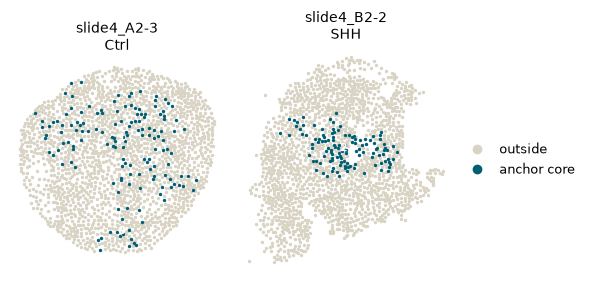

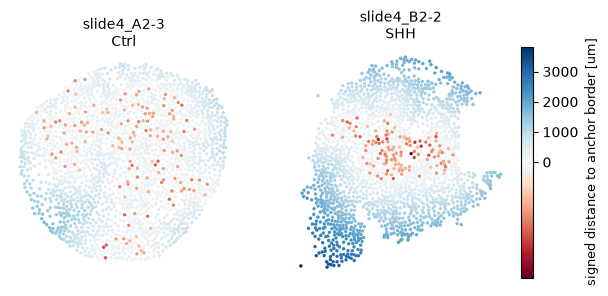

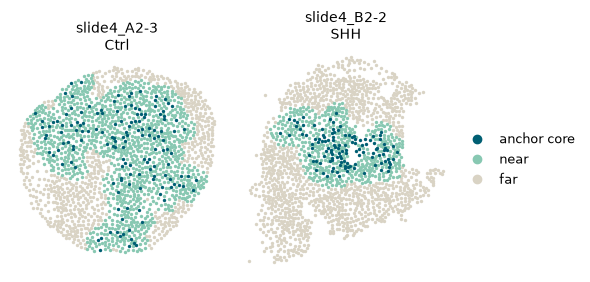

In [92]:
fig, _ = anchor_map(
    adata, anchor, focus=focus, samples=EXAMPLE_SLIDES, titles=PANEL_TITLES, show=False
)
save(fig, f"dim{DIM}_anchor_points")

fig, _ = signed_distance_map(adata, dist, samples=EXAMPLE_SLIDES, titles=PANEL_TITLES, show=False)
save(fig, f"dim{DIM}_signed_distance")

fig, _ = zone_map(adata, zone, samples=EXAMPLE_SLIDES, titles=PANEL_TITLES, show=False)
save(fig, f"dim{DIM}_zones")

plt.show()

### Did the dimension anchor on anything nameable?

`SHH_zone` is derived from `dist_to_SHH`, i.e. from the graft annotation and not from the model,
so it is an independent check on what the foci sit on. `log2_enrichment` is inside-vs-rest on
the fraction of cells; `inf` means a category is absent outside the foci, `-inf` absent inside.
A Ctrl slide with no focus contributes no rows &mdash; that is the point of showing it.

In [93]:
enr = anchor_enrichment(adata, anchor, "SHH_zone", samples=EXAMPLE_SLIDES)
display(enr.sort_values(["sample", "log2_enrichment"], ascending=[True, False]).round(2))

# The same question as a distance rather than a category: how far from the SHH source do the
# anchor cells sit, against the rest of their own slide.
sub = adata.obs.loc[adata.obs["sample"].isin(EXAMPLE_SLIDES)]
display(
    sub.groupby(["sample", KEY], observed=True)["dist_to_SHH"]
    .agg(["size", "median", "mean"])
    .round(1)
)

,sample,category,n_in,n_out,frac_in,frac_out,log2_enrichment
2,slide4_A2-3,medium,49,396,0.33,0.22,0.61
3,slide4_A2-3,far,77,832,0.52,0.45,0.19
1,slide4_A2-3,near,22,568,0.15,0.31,-1.07
0,slide4_A2-3,SHH,1,38,0.01,0.02,-1.63
5,slide4_B2-2,near,91,852,0.76,0.52,0.56
6,slide4_B2-2,medium,25,330,0.21,0.20,0.06
7,slide4_B2-2,far,4,309,0.03,0.19,-2.49
4,slide4_B2-2,SHH,0,161,0.00,0.10,-inf


size  median    mean
sample      44_anchor_dim5                      
slide4_A2-3 False           1834  2794.3  2762.9
            True             149  3055.0  2994.8
slide4_B2-2 False           1652  1461.8  1676.0
            True             120  1546.1  1628.8

### The dimension's own genes, across the two slides

`df_global` holds the union of every kept dimension's top genes with a signed score per
dimension, so the column for `DIM` ranks them *for this dimension*. The score is
`loading_x_sd`, which undoes the per-gene standardisation &mdash; without it a gene that is
near-silent on this panel wins on a tiny absolute effect divided by a tiny sd.

One colour scale per gene, shared across the two slides, so a row compares slides. Anchor cells
carry a red ring.

dim 5 top 4 genes (signed loading x sd):
PAX6     -0.184
HPRT1    -0.170
PTPRZ1   -0.165
STMN2    -0.162


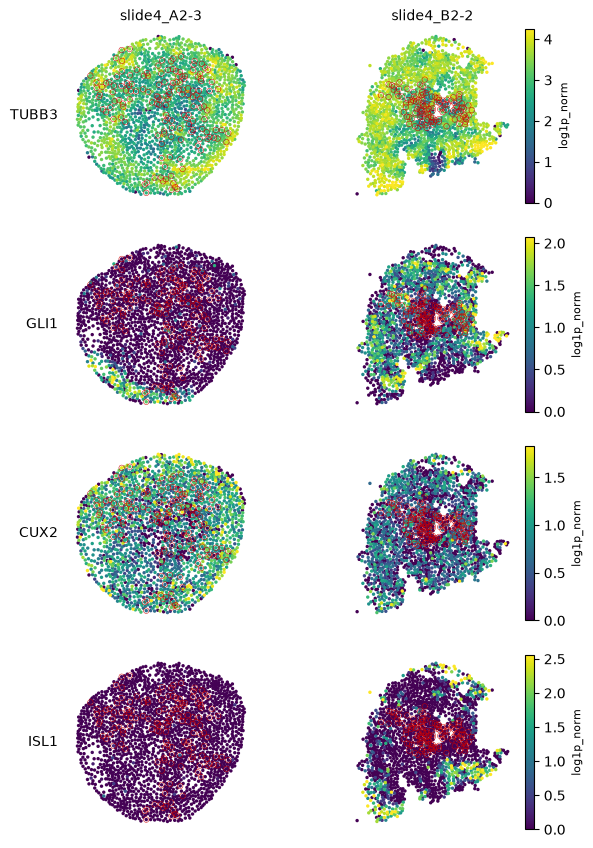

In [94]:
N_TOP = 4

assert str(DIM) in df.columns, (
    f"dim {DIM} is not a column of df_global (columns {list(df.columns)}). Re-run "
    "get_genes_dim above -- it scores the dims calculate_dim_importance kept."
)
TOP_GENES = df[str(DIM)].abs().nlargest(N_TOP).index.tolist()
print(f"dim {DIM} top {N_TOP} genes (signed loading x sd):")
print(df.loc[TOP_GENES, str(DIM)].round(3).to_string())

TOP_GENES = ['TUBB3', 'GLI1', 'CUX2', 'ISL1']

fig, _ = gene_maps(
    adata,
    TOP_GENES,
    samples=EXAMPLE_SLIDES,
    layer="log1p_norm",
    anchor=anchor,
    show=False,
)
save(fig, f"dim{DIM}_top_genes_slides")
plt.show()

### Expression against distance to the anchor border

The read-out. Per slide, because the anchors are per slide, and quantile-binned so the error
bars stay comparable along the axis.

How to read a panel:

* the shaded strip left of 0 is the anchor core, 0 is its border;
* the dashed line is the local component's reach;
* **a gene still trending to the right of the dashed line is trending over a distance no cell's
  neighbourhood spans** &mdash; only the global component can carry that, which is the concrete
  long-range interaction the dimension captured;
* a gene that has flattened before the dashed line is a neighbourhood effect and is *expected*
  to look like one; it is the contrast that makes the first kind readable.

The Ctrl slide has no focus for a graft-anchored dimension, so it has no distance axis and is
skipped with a message rather than silently plotted against `nan`.

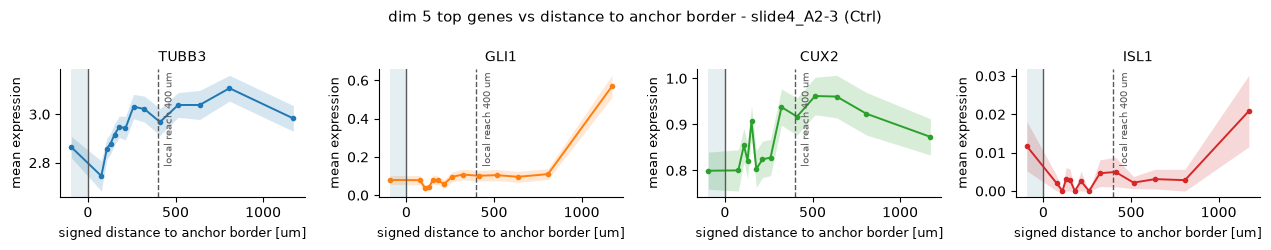

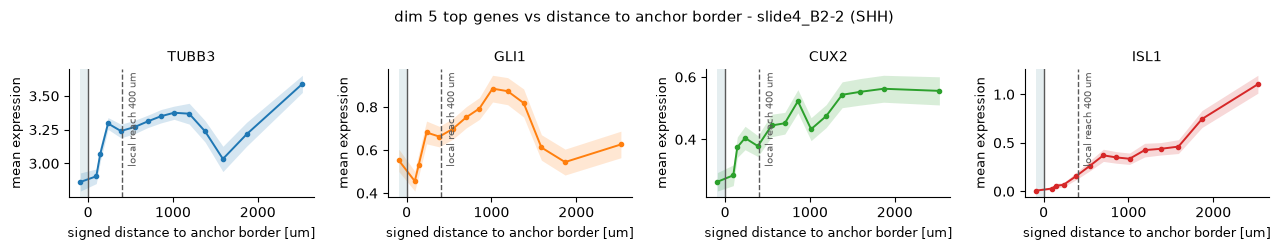

In [95]:
profiles = {}
for s in EXAMPLE_SLIDES:
    prof = profile_by_distance(
        adata,
        TOP_GENES,
        dist,
        layer="log1p_norm",  # what the decoders were trained on, so this is the loadings' scale
        mask=(adata.obs["sample"] == s).to_numpy(),
        n_bins=14,
        min_cells=15,
        binning="quantile",
    )
    if prof.empty:
        print(f"{s} ({CONDITION[s]}): no anchor focus, so no distance axis -- nothing to profile")
        continue
    profiles[s] = prof
    fig, _ = distance_profile(
        prof,
        genes=TOP_GENES,
        local_reach=REACH,
        one_panel_per_gene=True,
        ncols=len(TOP_GENES),
        title=f"dim {DIM} top genes vs distance to anchor border - {s} ({CONDITION[s]})",
        show=False,
    )
    save(fig, f"dim{DIM}_distance_profile_{s}")

    plt.show()

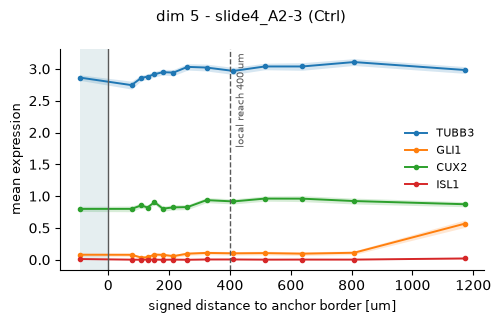

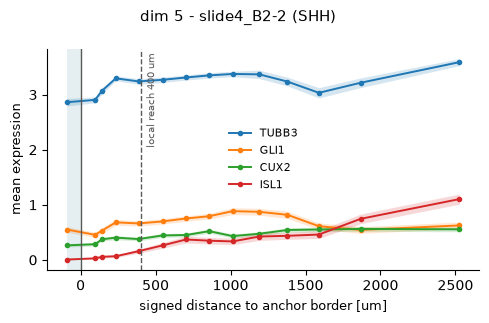

In [96]:
# The same profiles on one axes per slide, for the supplement: it is the panel that shows the
# genes' *relative* decay, which the per-gene panels above deliberately hide by rescaling each.
for s, prof in profiles.items():
    fig, _ = distance_profile(
        prof,
        genes=TOP_GENES,
        local_reach=REACH,
        title=f"dim {DIM} - {s} ({CONDITION[s]})",
        show=False,
    )
    save(fig, f"dim{DIM}_distance_profile_overlay_{s}")
plt.show()

In [97]:
# What the profile does past the local component's reach, as a number rather than a shape: the
# change in mean expression from the first bin beyond REACH to the last one. A gene whose
# `far_change` is a large fraction of its `total_change` keeps varying where no neighbourhood
# reaches, and is the concrete long-range read-out for this dimension.
#
# `frac_beyond_reach` is left blank for a gene that barely moves at all. It is a ratio of two
# differences, so a gene whose total change is within its own error bars gets an arbitrary one
# -- NKX6.1-style flat genes came back at 1.3 before this guard, which reads as "even more
# long-range than PTCH1" and means nothing.
summary = []
for s, prof in profiles.items():
    for g in TOP_GENES:
        sub = prof[prof["gene"] == g].sort_values("center")
        beyond = sub[sub["center"] > REACH]
        if len(beyond) < 2:
            continue
        far_change = beyond["mean"].iloc[-1] - beyond["mean"].iloc[0]
        total_change = sub["mean"].iloc[-1] - sub["mean"].iloc[0]
        # 2 x the typical bin's SEM: below that the gene has no gradient to apportion.
        resolvable = abs(total_change) > 2 * sub["sem"].median()
        summary.append(
            {
                "sample": s,
                "gene": g,
                # The innermost bin, which is the anchor core when the core holds enough cells
                # to make a bin of its own and the first band outside it otherwise.
                "inner_mean": sub["mean"].iloc[0],
                "outer_mean": sub["mean"].iloc[-1],
                "total_change": total_change,
                "far_change": far_change,
                "frac_beyond_reach": far_change / total_change if resolvable else np.nan,
            }
        )

summary = pd.DataFrame(summary)
summary.round(3)

,sample,gene,inner_mean,outer_mean,total_change,far_change,frac_beyond_reach
0,slide4_A2-3,TUBB3,2.864,2.983,0.118,0.015,0.123
1,slide4_A2-3,GLI1,0.080,0.568,0.489,0.467,0.955
2,slide4_A2-3,CUX2,0.799,0.873,0.074,-0.044,NaN
3,slide4_A2-3,ISL1,0.012,0.021,0.009,0.016,1.734
4,slide4_B2-2,TUBB3,2.863,3.590,0.727,0.320,0.440
5,slide4_B2-2,GLI1,0.552,0.626,0.074,-0.073,NaN
6,slide4_B2-2,CUX2,0.264,0.556,0.291,0.111,0.381
7,slide4_B2-2,ISL1,0.007,1.104,1.097,0.840,0.765


### What this shows

* The dimension resolves into a **small number of anchor points** on the SHH slide at a tail
  threshold tight enough to leave few cells, and into **none on the Ctrl slide** &mdash; so the
  foci are not an artefact of taking a fixed quantile of every slide.
* The foci are enriched for the annotated SHH source (`SHH_zone`), an annotation the model never
  saw, and the anchor cells sit far closer to the graft than the rest of their slide.
* The dimension's top genes are **graded over thousands of micrometres** from that border, and a
  substantial part of that change happens **beyond the local component's reach** (`far_change`
  against `total_change` in the table above). A local, neighbourhood-scale model has no
  mechanism for that gradient; the global component is what represents it.

This is the concrete example to put in the response: one dimension, its anchor points, the
tissue split around them, and its genes' expression as a function of that distance, with the
local component's reach marked so the long-range part is separated from the neighbourhood part
rather than asserted.